In [4]:
from pathlib import Path
import pandas as pd
from tqdm.auto import tqdm

In [5]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "ec2"
cols = ["record", "price", "timestamp", "instance_type", "os", "az"]

files = sorted(RAW.glob("data.us-east-1.2019-*.xz"))
print(len(files), "berkas")

parts = []
for f in tqdm(files):
    d = pd.read_csv(f, sep="\t", header=None, names=cols, compression="xz",
                    usecols=[0, 1, 2, 3, 4, 5])
    parts.append(d)
raw = pd.concat(parts, ignore_index=True)
print("baris mentah:", len(raw))
print("jenis record:", raw["record"].unique())

raw["timestamp"] = pd.to_datetime(raw["timestamp"], utc=True)
raw = (raw.drop(columns="record")
          .drop_duplicates()                       # snapshot harian tumpang tindih
          .sort_values(["instance_type", "os", "az", "timestamp"])
          .reset_index(drop=True))
print("baris unik:", len(raw))
print(raw["timestamp"].min(), raw["timestamp"].max())

# ukuran dasar per seri
g = raw.groupby(["instance_type", "os", "az"])["price"]
stats = pd.DataFrame({
    "n_catatan": g.size(),
    "n_harga_berbeda": g.nunique(),
    "median": g.median(),
    "min": g.min(), "max": g.max(),
})
stats["rentang_rel"] = (stats["max"] - stats["min"]) / stats["median"]
print(stats["n_catatan"].describe())
print(stats.sort_values("n_catatan", ascending=False).head(10))
print(stats["rentang_rel"].describe())

347 berkas


100%|██████████| 347/347 [00:06<00:00, 57.62it/s]


baris mentah: 3977358
jenis record: <StringArray>
['SPOTINSTANCEPRICE']
Length: 1, dtype: str
baris unik: 2582550
2018-12-30 06:07:54+00:00 2019-12-31 07:59:15+00:00
count    5530.000000
mean      467.007233
std       351.691205
min        18.000000
25%       224.250000
50%       410.000000
75%       534.000000
max      1525.000000
Name: n_catatan, dtype: float64
                                                  n_catatan  n_harga_berbeda   median     min     max  rentang_rel
instance_type os                      az                                                                          
r3.4xlarge    SUSE Linux (Amazon VPC) us-east-1e       1525              936  0.43700  0.3618  0.7573     0.905034
              Linux/UNIX (Amazon VPC) us-east-1e       1525              936  0.33700  0.2618  0.6573     1.173591
r4.8xlarge    Linux/UNIX (Amazon VPC) us-east-1a       1521              980  0.63050  0.5547  0.8265     0.431086
              SUSE Linux (Amazon VPC) us-east-1a       1521

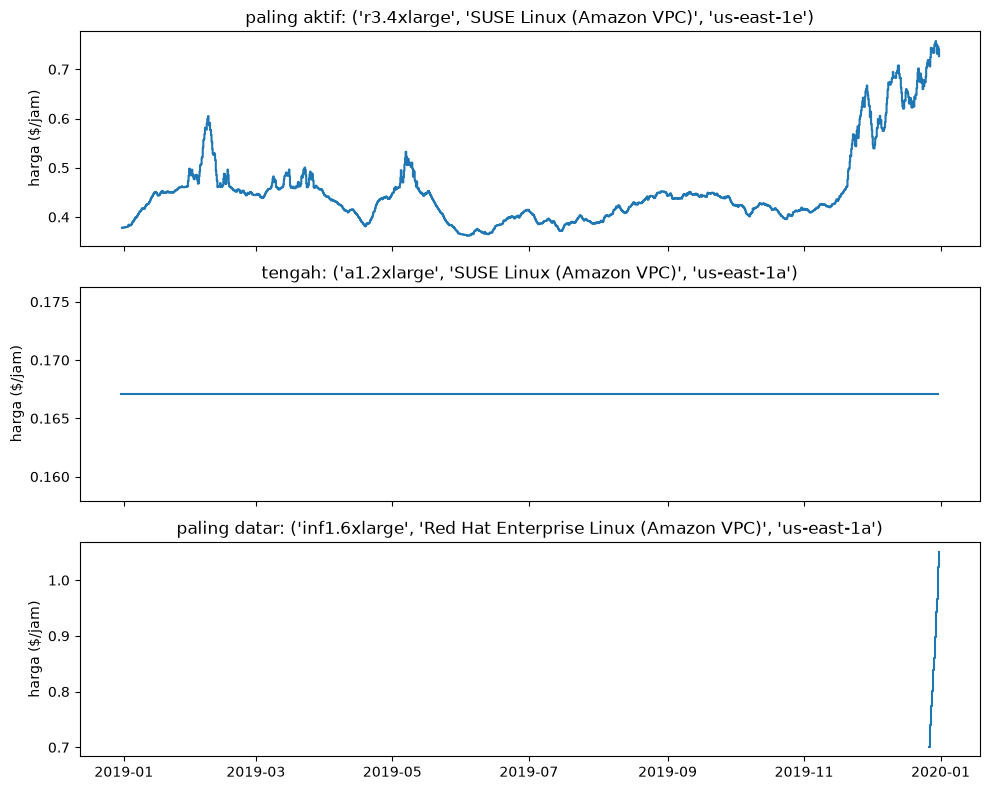

In [6]:
import matplotlib.pyplot as plt

order = stats.sort_values("n_catatan")
picks = {"paling aktif": order.index[-1],
         "tengah": order.index[len(order) // 2],
         "paling datar": order.index[0]}

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, (nama, key) in zip(axes, picks.items()):
    s = raw[(raw.instance_type == key[0]) & (raw.os == key[1]) & (raw.az == key[2])]
    ax.step(s["timestamp"], s["price"], where="post")
    ax.set_title(f"{nama}: {key}")
    ax.set_ylabel("harga ($/jam)")
plt.tight_layout()
plt.show()

In [7]:
def series(key):
    return (raw[(raw.instance_type == key[0]) & (raw.os == key[1]) & (raw.az == key[2])]
            .sort_values("timestamp"))

for nama, key in picks.items():
    s = series(key)
    n_chg = int((s["price"].diff().fillna(0) != 0).sum())
    dt = s["timestamp"].diff().dropna().dt.total_seconds() / 3600
    print(nama, key)
    print("  catatan:", len(s), "| perubahan harga:", n_chg, "| harga berbeda:", s["price"].nunique())
    print("  awal:", s["timestamp"].min(), "| akhir:", s["timestamp"].max())
    print("  selang antar catatan (jam): median", round(dt.median(), 2), "| maks", round(dt.max(), 1))

paling aktif ('r3.4xlarge', 'SUSE Linux (Amazon VPC)', 'us-east-1e')
  catatan: 1525 | perubahan harga: 1430 | harga berbeda: 936
  awal: 2018-12-31 03:58:03+00:00 | akhir: 2019-12-31 07:50:24+00:00
  selang antar catatan (jam): median 5.86 | maks 19.4
tengah ('a1.2xlarge', 'SUSE Linux (Amazon VPC)', 'us-east-1a')
  catatan: 410 | perubahan harga: 0 | harga berbeda: 1
  awal: 2018-12-30 12:59:21+00:00 | akhir: 2019-12-30 18:55:42+00:00
  selang antar catatan (jam): median 24.01 | maks 24.0
paling datar ('inf1.6xlarge', 'Red Hat Enterprise Linux (Amazon VPC)', 'us-east-1a')
  catatan: 18 | perubahan harga: 17 | harga berbeda: 18
  awal: 2019-12-26 23:25:37+00:00 | akhir: 2019-12-31 06:26:11+00:00
  selang antar catatan (jam): median 6.14 | maks 7.3


In [8]:
lin = ("r3.4xlarge", "Linux/UNIX (Amazon VPC)", "us-east-1e")
sus = ("r3.4xlarge", "SUSE Linux (Amazon VPC)", "us-east-1e")
a = series(lin).set_index("timestamp")["price"].rename("linux")
b = series(sus).set_index("timestamp")["price"].rename("suse")
a = a[~a.index.duplicated(keep="last")]; b = b[~b.index.duplicated(keep="last")]
j = pd.concat([a, b], axis=1).dropna()
print(len(a), len(b), len(j))
print((j["suse"] - j["linux"]).describe())      # std ~ 0 berarti offset tetap

1525 1525 1525
count    1.525000e+03
mean     1.000000e-01
std      3.545826e-17
min      1.000000e-01
25%      1.000000e-01
50%      1.000000e-01
75%      1.000000e-01
max      1.000000e-01
dtype: float64


In [9]:
import numpy as np

def to_hourly(s):
    x = s.set_index("timestamp")["price"]
    x = x[~x.index.duplicated(keep="last")]
    grid = pd.date_range(x.index.min().floor("h"), x.index.max().ceil("h"), freq="h", tz="UTC")
    return x.reindex(x.index.union(grid)).ffill().reindex(grid).dropna()

def VW(x):
    z = (x / x.median()).to_numpy()
    return np.abs(np.diff(z)).sum(), np.abs(z - z.mean()).sum(), len(z)

for nama, key in picks.items():
    V, W, n = VW(to_hourly(series(key)))
    print(f"{nama:13s} jam={n:5d}  V={V:8.3f}  W={W:9.1f}  W/n={W/n:.4f}")

paling aktif  jam= 8765  V=   9.593  W=   1037.3  W/n=0.1183
tengah        jam= 8767  V=   0.000  W=      0.0  W/n=0.0000
paling datar  jam=  104  V=   0.406  W=      9.8  W/n=0.0946


In [10]:
def ar1_event(s):
    d = np.diff(s["price"].to_numpy()); d = d[d != 0]
    return None if len(d) < 30 else (len(d), round(float(np.corrcoef(d[:-1], d[1:])[0, 1]), 3))

for nama, key in picks.items():
    print(nama, ar1_event(series(key)))      # bandingkan dengan -0.7 (Ben-Yehuda, data 2010)

paling aktif (1430, 0.208)
tengah None
paling datar None


In [11]:
lin = raw[raw["os"] == "Linux/UNIX (Amazon VPC)"].copy()
keys = ["instance_type", "az"]
lin = lin.sort_values(keys + ["timestamp"])
lin["chg"] = lin.groupby(keys)["price"].diff().fillna(0) != 0
lin["dt_h"] = lin.groupby(keys)["timestamp"].diff().dt.total_seconds() / 3600

per = lin.groupby(keys).agg(
    n_catatan=("price", "size"),
    n_perubahan=("chg", "sum"),
    hari=("timestamp", lambda t: (t.max() - t.min()).days),
    median=("price", "median"),
    rentang_rel=("price", lambda p: (p.max() - p.min()) / p.median()),
)
chg_dt = lin[lin["chg"]].groupby(keys)["dt_h"].median().rename("selang_perubahan_jam")
per = per.join(chg_dt)

per["kelas"] = np.select(
    [per.hari < 300, per.n_perubahan == 0, per.n_perubahan < 100],
    ["pendek", "datar", "jarang"], default="aktif")
print(len(per), "seri Linux/UNIX")
print(per["kelas"].value_counts())
print(per[per.kelas == "aktif"][["n_perubahan", "selang_perubahan_jam", "rentang_rel"]].describe())

1251 seri Linux/UNIX
kelas
aktif     553
pendek    442
jarang    141
datar     115
Name: count, dtype: int64
       n_perubahan  selang_perubahan_jam  rentang_rel
count   553.000000            553.000000   553.000000
mean    792.669078              6.264314     0.786221
std     457.840873              0.532643     1.082625
min     106.000000              5.718056     0.019449
25%     328.000000              6.004583     0.256777
50%     796.000000              6.133333     0.381702
75%    1252.000000              6.277222     0.821364
max    1437.000000             11.078472     9.000000


In [12]:
piv = raw.pivot_table(index=["instance_type", "az", "timestamp"],
                      columns="os", values="price", aggfunc="last")
lin_c = "Linux/UNIX (Amazon VPC)"
for c in [x for x in piv.columns if x != lin_c]:
    d = (piv[c] - piv[lin_c]).dropna()
    g = d.groupby(level=[0, 1]).std().dropna()
    print(c, "| pasangan:", len(g), "| std selisih maks:", float(g.max()), "| persen std<1e-6:", float((g < 1e-6).mean()))

Linux/UNIX | pasangan: 143 | std selisih maks: 0.10557013505465905 | persen std<1e-6: 0.40559440559440557
Red Hat Enterprise Linux | pasangan: 137 | std selisih maks: 0.13152850793448134 | persen std<1e-6: 0.5255474452554745
Red Hat Enterprise Linux (Amazon VPC) | pasangan: 1243 | std selisih maks: 1.3104349502126814e-15 | persen std<1e-6: 1.0
SUSE Linux | pasangan: 143 | std selisih maks: 0.10557013505465905 | persen std<1e-6: 0.40559440559440557
SUSE Linux (Amazon VPC) | pasangan: 1251 | std selisih maks: 1.222874767474421e-15 | persen std<1e-6: 1.0
Windows | pasangan: 138 | std selisih maks: 0.11527891810420511 | persen std<1e-6: 0.2753623188405797
Windows (Amazon VPC) | pasangan: 1135 | std selisih maks: 1.334967512985974 | persen std<1e-6: 0.2748898678414097


In [13]:
OUT = ROOT / "data" / "processed"; OUT.mkdir(parents=True, exist_ok=True)
lin[["instance_type", "az", "timestamp", "price"]].to_csv(
    OUT / "ec2_us-east-1_2019_linux.csv.gz", index=False)

In [14]:
import pandas as pd
import numpy as np
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

OUT = ROOT / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)
def simpan(df, nama):                      # nama berisi "summary" agar lolos aturan .gitignore
    df.to_csv(OUT / f"ec2_{nama}_summary.csv")

# ---- T0. Sampel MENTAH, persis seperti isi berkas (sebelum dibersihkan) ----
cols = ["record", "price", "timestamp", "instance_type", "os", "az"]
f0 = sorted(RAW.glob("data.us-east-1.2019-09-29*.xz"))[0]
t0 = pd.read_csv(f0, sep="\t", header=None, names=cols, nrows=8, compression="xz")
print("T0. Contoh baris mentah dari", f0.name)
display(t0)

# ---- T1. Skema kolom ----
skema = pd.DataFrame({
    "kolom": cols,
    "tipe": t0.dtypes.astype(str).values,
    "arti": ["jenis catatan (selalu sama)", "harga spot (USD per jam)",
             "waktu harga mulai berlaku", "tipe instans", "sistem operasi/produk",
             "zona ketersediaan"],
    "contoh": t0.iloc[0].astype(str).values,
})
print("T1. Skema kolom")
display(skema)

# ---- T2. Ringkasan dataset yang dipakai ----
n_mentah = sum(len(p) for p in parts)
ringkas = pd.Series({
    "region": "us-east-1",
    "berkas .xz dibaca": len(files),
    "baris mentah": n_mentah,
    "baris unik (setelah deduplikasi)": len(raw),
    "persen duplikat": round(100 * (1 - len(raw) / n_mentah), 1),
    "tipe instans berbeda": raw["instance_type"].nunique(),
    "zona (az) berbeda": raw["az"].nunique(),
    "produk OS berbeda": raw["os"].nunique(),
    "seri (tipe x OS x zona)": raw.groupby(["instance_type", "os", "az"]).ngroups,
    "waktu awal (UTC)": str(raw["timestamp"].min()),
    "waktu akhir (UTC)": str(raw["timestamp"].max()),
}, name="nilai").to_frame()
print("T2. Ringkasan dataset (us-east-1, berkas 2019)")
display(ringkas)

# ---- T3. Per sistem operasi ----
seri_os = raw.drop_duplicates(["instance_type", "os", "az"]).groupby("os").size().rename("seri")
t_os = (raw.groupby("os").agg(baris=("price", "size"), harga_median=("price", "median"))
          .join(seri_os).sort_values("baris", ascending=False))
print("T3. Per sistem operasi")
display(t_os)

# ---- T4. Per zona ketersediaan ----
seri_az = raw.drop_duplicates(["instance_type", "os", "az"]).groupby("az").size().rename("seri")
t_az = (raw.groupby("az").agg(baris=("price", "size")).join(seri_az)
          .sort_values("baris", ascending=False))
print("T4. Per zona ketersediaan")
display(t_az)

# ---- T5. Per keluarga instans (15 teratas menurut jumlah baris) ----
raw["keluarga"] = raw["instance_type"].str.split(".").str[0]
t_fam = (raw.groupby("keluarga").agg(baris=("price", "size"),
                                     tipe=("instance_type", "nunique"),
                                     harga_median=("price", "median"))
           .sort_values("baris", ascending=False).head(15))
print("T5. Per keluarga instans (15 teratas)")
display(t_fam)

# ---- T6. Kelas seri Linux/UNIX ----
t_kelas = per["kelas"].value_counts().to_frame("jumlah_seri")
t_kelas["persen"] = (100 * t_kelas["jumlah_seri"] / t_kelas["jumlah_seri"].sum()).round(1)
t_kelas["median_perubahan"] = per.groupby("kelas")["n_perubahan"].median()
t_kelas["median_rentang_rel"] = per.groupby("kelas")["rentang_rel"].median().round(3)
print("T6. Kelas seri Linux/UNIX")
display(t_kelas)

# ---- T7. Contoh deret harga: satu seri 'khas' per kelas ----
def contoh(kelas, n=6):
    sub = per[per["kelas"] == kelas].sort_values("n_perubahan")
    k = sub.index[len(sub) // 2]                      # seri median, bukan yang ekstrem
    s = lin[(lin["instance_type"] == k[0]) & (lin["az"] == k[1])][["timestamp", "price"]]
    return k, s.head(n)
for kelas in ["aktif", "jarang", "datar"]:
    k, s = contoh(kelas)
    print(f"T7. Contoh seri kelas '{kelas}': {k}")
    display(s.reset_index(drop=True))

# ---- T8. Statistik harga (USD/jam), seri Linux/UNIX ----
print("T8. Statistik harga seluruh baris Linux/UNIX")
display(lin["price"].describe().to_frame("price").round(4))

# ---- simpan tabel kecil (aman untuk di-commit) ----
for nama, t in {"skema": skema, "ringkasan": ringkas, "os": t_os, "az": t_az,
                "keluarga": t_fam, "kelas": t_kelas}.items():
    simpan(t, nama)
per.to_csv(OUT / "ec2_us-east-1_2019_linux_series_summary.csv")
print("Tersimpan di", OUT)

T0. Contoh baris mentah dari data.us-east-1.2019-09-29T00:06:02-07:00.xz


,record,price,timestamp,instance_type,os,az
0,SPOTINSTANCEPRICE,0.3155,2019-09-29T00:01:56-0700,m5d.2xlarge,Red Hat Enterprise Linux (Amazon VPC),us-east-1d
1,SPOTINSTANCEPRICE,0.2855,2019-09-29T00:01:56-0700,m5d.2xlarge,SUSE Linux (Amazon VPC),us-east-1d
2,SPOTINSTANCEPRICE,0.1855,2019-09-29T00:01:56-0700,m5d.2xlarge,Linux/UNIX (Amazon VPC),us-east-1d
3,SPOTINSTANCEPRICE,0.2062,2019-09-29T00:01:55-0700,i3en.xlarge,Red Hat Enterprise Linux (Amazon VPC),us-east-1a
4,SPOTINSTANCEPRICE,0.2462,2019-09-29T00:01:55-0700,i3en.xlarge,SUSE Linux (Amazon VPC),us-east-1a
5,SPOTINSTANCEPRICE,0.1462,2019-09-29T00:01:55-0700,i3en.xlarge,Linux/UNIX (Amazon VPC),us-east-1a
6,SPOTINSTANCEPRICE,0.4775,2019-09-29T00:01:54-0700,r3.4xlarge,Red Hat Enterprise Linux (Amazon VPC),us-east-1b
7,SPOTINSTANCEPRICE,0.4475,2019-09-29T00:01:54-0700,r3.4xlarge,SUSE Linux (Amazon VPC),us-east-1b


T1. Skema kolom


,kolom,tipe,arti,contoh
0,record,str,jenis catatan (selalu sama),SPOTINSTANCEPRICE
1,price,float64,harga spot (USD per jam),0.3155
2,timestamp,str,waktu harga mulai berlaku,2019-09-29T00:01:56-0700
3,instance_type,str,tipe instans,m5d.2xlarge
4,os,str,sistem operasi/produk,Red Hat Enterprise Linux (Amazon VPC)
5,az,str,zona ketersediaan,us-east-1d


T2. Ringkasan dataset (us-east-1, berkas 2019)


...

T7. Contoh seri kelas 'datar': ('m1.small', 'us-east-1b')


,timestamp,price
0,2018-12-30 19:58:03+00:00,0.0044
1,2018-12-31 19:58:07+00:00,0.0044
2,2019-01-01 19:58:08+00:00,0.0044
3,2019-01-02 01:58:04+00:00,0.0044
4,2019-01-03 01:58:18+00:00,0.0044
5,2019-01-04 01:58:18+00:00,0.0044


T8. Statistik harga seluruh baris Linux/UNIX


,price
count,746986.0000
mean,0.6854
std,1.4542
min,0.0014
25%,0.0951
50%,0.2948
75%,0.8162
max,31.2120


Tersimpan di /home/frathol/KULIAH/RDA/dollar-auction-bandit/data/processed


In [15]:
def lag1(p):
    d = p.diff().dropna().to_numpy(); d = d[d != 0]
    return np.corrcoef(d[:-1], d[1:])[0, 1] if len(d) >= 30 else np.nan

ac = lin.groupby(["instance_type", "az"])["price"].apply(lag1).dropna()
print(ac.describe())
print("persen seri dengan lag-1 > 0:", round(float((ac > 0).mean()), 3))

count    822.000000
mean       0.476091
std        0.274553
min       -0.882274
25%        0.298523
50%        0.453460
75%        0.716049
max        0.932252
Name: price, dtype: float64
persen seri dengan lag-1 > 0: 0.962


In [16]:
n_chg = lin.groupby(["instance_type", "az"])["price"].apply(
    lambda p: int((p.diff().fillna(0) != 0).sum()))
res = pd.DataFrame({"lag1": ac, "n": n_chg}).dropna().reset_index()
res["se"] = 1 / np.sqrt(res["n"])
res["sig_pos"] = res["lag1"] > 2 * res["se"]
res["sig_neg"] = res["lag1"] < -2 * res["se"]
res["keluarga"] = res["instance_type"].str.split(".").str[0]

print("Semua seri:", len(res), "| signifikan positif:", round(res.sig_pos.mean(), 3),
      "| signifikan negatif:", round(res.sig_neg.mean(), 3))
print(res.groupby("az").agg(seri=("lag1", "size"), median_lag1=("lag1", "median"),
                            frac_pos=("sig_pos", "mean"), frac_neg=("sig_neg", "mean")).round(3))
print(res.groupby("keluarga").agg(seri=("lag1", "size"), median_lag1=("lag1", "median"))
        .sort_values("seri", ascending=False).head(10).round(3))

Semua seri: 822 | signifikan positif: 0.918 | signifikan negatif: 0.015
            seri  median_lag1  frac_pos  frac_neg
az                                               
us-east-1a   169        0.433     0.893     0.012
us-east-1b   163        0.414     0.933     0.006
us-east-1c   153        0.551     0.935     0.026
us-east-1d   175        0.446     0.909     0.017
us-east-1e    46        0.372     0.913     0.022
us-east-1f   116        0.500     0.931     0.009
          seri  median_lag1
keluarga                   
r5          45        0.336
r5d         42        0.639
m5          41        0.363
r4          35        0.375
c5          35        0.292
m4          33        0.338
z1d         33        0.816
r5a         32        0.402
i3          32        0.431
c5d         32        0.323
